# 📱 Mobile Phone Price Analysis — EDA + Machine Learning Project

**Objective:** Explore a mobile phone dataset, find & fix data-quality mistakes, understand what drives phone prices, and build a model that predicts the **price category** (Budget / Mid-range / Premium) from phone specifications.

**Workflow**
1. Load data  →  2. Audit data quality (find mistakes)  →  3. Clean data  →  4. EDA (univariate, bivariate, correlation, outliers)
5. Feature engineering  →  6. Model training & evaluation (Accuracy, Precision, Recall, F1)  →  7. Dynamic user input & prediction

## 1. Import Libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, r2_score)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## 2. Load the Dataset

In [2]:
# Make sure 'mobile_phone_price_eda.csv' is in the same folder as this notebook
raw = pd.read_csv("mobile_phone_price_eda.csv")
df = raw.copy()

print("Shape (rows, columns):", df.shape)
df.head(10)

Shape (rows, columns): (1505, 12)


,brand,model,price,ram,storage,battery,screen_size,camera,rating,5G,processor,os
0,Xiaomi,Redmi Note 14,42300,4,256,5002.0,6.59,64.0,3.9,Yes,Apple A-series,Android
1,Nothing,Phone 3a Pro,57900,6,128,5730.0,6.23,50.0,4.5,Yes,MediaTek Dimensity,Android
2,Oppo,Find X8,50600,8,256,4444.0,6.77,50.0,4.4,No,MediaTek Dimensity,Android
3,Vivo,X100,51600,8,256,5304.0,6.11,48.0,4.0,Yes,Snapdragon,Android
4,Apple,iPhone 14,91700,8,256,5212.0,6.25,64.0,3.9,Yes,MediaTek Dimensity,Android
5,Apple,iPhone 13,101800,8,256,4603.0,6.62,108.0,4.6,Yes,Snapdragon,Android
6,Samsung,Galaxy S24 FE,61200,8,512,5660.0,6.74,64.0,4.1,Yes,MediaTek Dimensity,Android
7,Google,Pixel 9 Pro XL,66400,4,256,5243.0,6.92,64.0,4.2,Yes,Snapdragon,Android
8,Vivo,V40,55900,8,256,4772.0,6.73,48.0,4.7,Yes,Snapdragon,Android
9,Oppo,Find X8,67500,16,256,4163.0,6.70,48.0,5.0,Yes,Snapdragon,Android


In [ ]:
df.info()

In [ ]:
df.describe().T

## 3. Data Quality Audit — Finding the Mistakes
Before analysing, we check the file for errors. Real-world data usually has these problems:
duplicates, missing values, and **logically impossible combinations** (e.g. an iPhone running Android).

In [3]:
audit = {}

# 1) Duplicate rows
audit["Duplicate rows"] = int(df.duplicated().sum())

# 2) Missing values
missing = df.isnull().sum()
audit["Missing values (total cells)"] = int(missing.sum())

# 3) Logical mistakes
audit["Apple phones NOT running iOS"]            = int(((df["brand"] == "Apple") & (df["os"] != "iOS")).sum())
audit["Non-Apple phones running iOS"]            = int(((df["brand"] != "Apple") & (df["os"] == "iOS")).sum())
audit["Apple chip (A-series) in non-Apple phone"] = int(((df["brand"] != "Apple") & (df["processor"] == "Apple A-series")).sum())
audit["Non-Apple chip in Apple phone"]           = int(((df["brand"] == "Apple") & (df["processor"] != "Apple A-series")).sum())
audit["Google Tensor in non-Google phone"]       = int(((df["brand"] != "Google") & (df["processor"] == "Google Tensor")).sum())
audit["Exynos in non-Samsung phone"]             = int(((df["brand"] != "Samsung") & (df["processor"] == "Exynos")).sum())
audit["Apple phones marked 'No 5G' (all iPhone 12+ have 5G)"] = int(((df["brand"] == "Apple") & (df["5G"] == "No")).sum())
audit["Apple phones with RAM > 8 GB (impossible)"] = int(((df["brand"] == "Apple") & (df["ram"] > 8)).sum())
audit["Rating outside 1-5"]                      = int(((df["rating"] < 1) | (df["rating"] > 5)).sum())

pd.DataFrame.from_dict(audit, orient="index", columns=["Count"])

,Count
Duplicate rows,5
Missing values (total cells),45
Apple phones NOT running iOS,108
Non-Apple phones running iOS,246
Apple chip (A-series) in non-Apple phone,148
Non-Apple chip in Apple phone,121
Google Tensor in non-Google phone,113
Exynos in non-Samsung phone,171
Apple phones marked 'No 5G' (all iPhone 12+ have 5G),30
Apple phones with RAM > 8 GB (impossible),35


In [4]:
print("Missing values per column:")
print(missing[missing > 0])

Missing values per column:
battery    15
camera     15
rating     15
dtype: int64


## 4. Data Cleaning
Fixes applied:

| # | Problem | Fix |
|---|---------|-----|
| 1 | Duplicate rows | Drop duplicates |
| 2 | Column named `5G` (starts with a digit, awkward in code) | Rename to `is_5g` |
| 3 | Missing `battery`, `camera`, `rating` | Fill with the **median of the same phone model** (fallback: overall median) |
| 4 | Apple phone not on iOS / other brands on iOS | iOS only for Apple, Android for everyone else |
| 5 | Brand-exclusive chips used by wrong brand | Apple→A-series, Google→Tensor, Exynos→Samsung only; others re-assigned by price tier |
| 6 | Apple phones with no 5G | Set to Yes |
| 7 | Apple RAM above 8 GB | Capped at 8 GB |

In [5]:
df = raw.copy()

# 1) Remove duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {before - len(df)}")

# 2) Clean column names & text
df = df.rename(columns={"5G": "is_5g"})
df.columns = [c.strip().lower() for c in df.columns]
for c in ["brand", "model", "is_5g", "processor", "os"]:
    df[c] = df[c].astype(str).str.strip()

# 3) Fill missing numeric values using the median of the same model
for col in ["battery", "camera", "rating"]:
    df[col] = df[col].fillna(df.groupby("model")[col].transform("median"))
    df[col] = df[col].fillna(df[col].median())
df["battery"] = df["battery"].round().astype(int)
df["camera"]  = df["camera"].astype(int)
df["rating"]  = df["rating"].round(1)

# 4) Operating system must match the brand
df["os"] = np.where(df["brand"] == "Apple", "iOS", "Android")

# 5) Processor must match the brand
def fix_processor(row):
    b, p, price = row["brand"], row["processor"], row["price"]
    if b == "Apple":
        return "Apple A-series"
    if b == "Google":
        return "Google Tensor"
    if b == "Samsung":
        return p if p in ("Exynos", "Snapdragon", "MediaTek Dimensity", "Unisoc") else "Exynos"
    # all other Android brands: no Apple / Tensor / Exynos chips
    if p in ("Apple A-series", "Google Tensor", "Exynos"):
        return "Snapdragon" if price >= 50000 else "MediaTek Dimensity"
    return p

df["processor"] = df.apply(fix_processor, axis=1)

# 6) Every iPhone sold in this price range supports 5G
df.loc[df["brand"] == "Apple", "is_5g"] = "Yes"

# 7) iPhones never have more than 8 GB RAM
df.loc[(df["brand"] == "Apple") & (df["ram"] > 8), "ram"] = 8

print("Final shape:", df.shape)
print("Remaining missing values:", int(df.isnull().sum().sum()))

Duplicates removed: 5
Final shape: (1500, 12)
Remaining missing values: 0


In [6]:
# Re-run the audit on the cleaned data -> every mistake count should be 0
check = {
    "Duplicates": int(df.duplicated().sum()),
    "Missing": int(df.isnull().sum().sum()),
    "Apple not iOS": int(((df.brand == "Apple") & (df.os != "iOS")).sum()),
    "Non-Apple on iOS": int(((df.brand != "Apple") & (df.os == "iOS")).sum()),
    "Wrong Apple chip usage": int((((df.brand != "Apple") & (df.processor == "Apple A-series")) | ((df.brand == "Apple") & (df.processor != "Apple A-series"))).sum()),
    "Tensor outside Google": int(((df.brand != "Google") & (df.processor == "Google Tensor")).sum()),
    "Exynos outside Samsung": int(((df.brand != "Samsung") & (df.processor == "Exynos")).sum()),
    "Apple without 5G": int(((df.brand == "Apple") & (df.is_5g == "No")).sum()),
    "Apple RAM > 8": int(((df.brand == "Apple") & (df.ram > 8)).sum()),
}
display(pd.DataFrame.from_dict(check, orient="index", columns=["Count after cleaning"]))

# Save the corrected file
df.to_csv("mobile_phone_price_eda_cleaned.csv", index=False)
print("Saved -> mobile_phone_price_eda_cleaned.csv")

,Count after cleaning
Duplicates,0
Missing,0
Apple not iOS,0
Non-Apple on iOS,0
Wrong Apple chip usage,0
Tensor outside Google,0
Exynos outside Samsung,0
Apple without 5G,0
Apple RAM > 8,0


Saved -> mobile_phone_price_eda_cleaned.csv


## 5. Exploratory Data Analysis (EDA)

### 5.1 Basic Statistics

In [7]:
print("Numerical columns:", df.select_dtypes(include="number").columns.tolist())
print("Categorical columns:", df.select_dtypes(exclude="number").columns.tolist())
df.describe().T

Numerical columns: ['price', 'ram', 'storage', 'battery', 'screen_size', 'camera', 'rating']
Categorical columns: ['brand', 'model', 'is_5g', 'processor', 'os']


,count,mean,std,min,25%,50%,75%,max
price,1500.0,58889.400000,17439.482733,21700.0,46200.00,55500.00,68925.0000,131800.0
ram,1500.0,8.736000,4.148306,4.0,6.00,8.00,12.0000,24.0
storage,1500.0,247.338667,189.381494,64.0,128.00,256.00,256.0000,1024.0
battery,1500.0,4980.784667,455.398572,3500.0,4690.00,4977.00,5276.0000,6458.0
screen_size,1500.0,6.534660,0.255855,6.1,6.32,6.53,6.7425,7.0
camera,1500.0,66.533333,42.887424,12.0,48.00,50.00,64.0000,200.0
rating,1500.0,4.096800,0.438221,2.7,3.80,4.10,4.4000,5.0


In [8]:
df.describe(include="object").T

,count,unique,top,freq
brand,1500,10,Samsung,230
model,1500,50,Galaxy A55,59
is_5g,1500,2,Yes,1115
processor,1500,6,Snapdragon,526
os,1500,2,Android,1366


### 5.2 Univariate Analysis

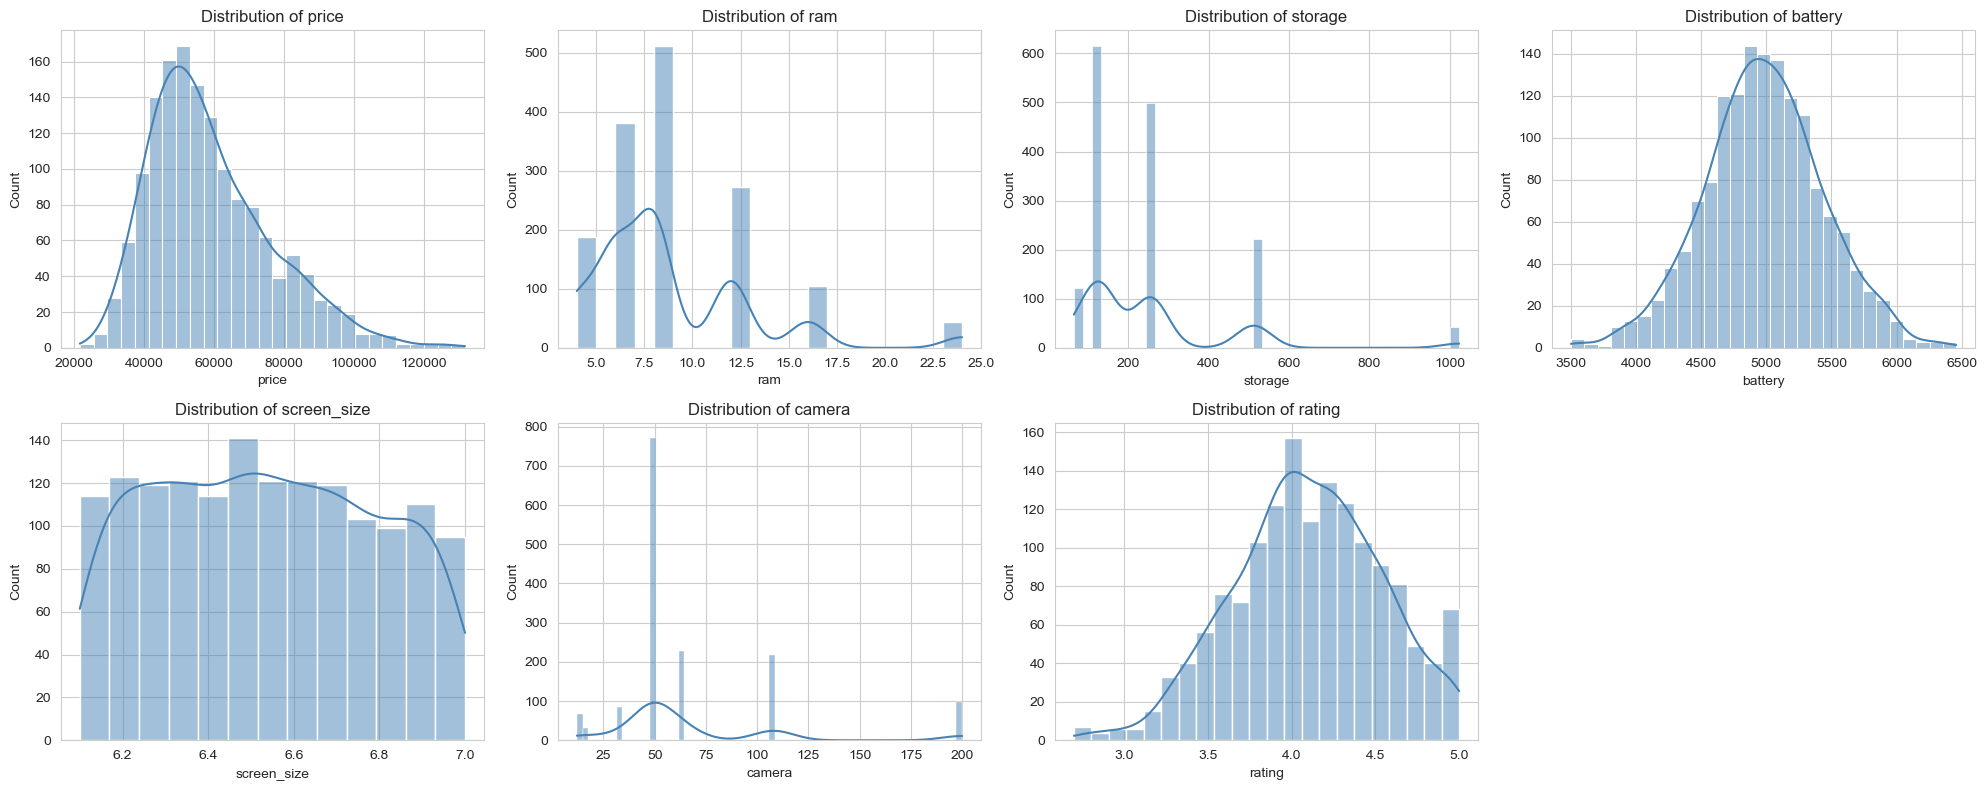

In [9]:
num_cols = ["price", "ram", "storage", "battery", "screen_size", "camera", "rating"]

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution of {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

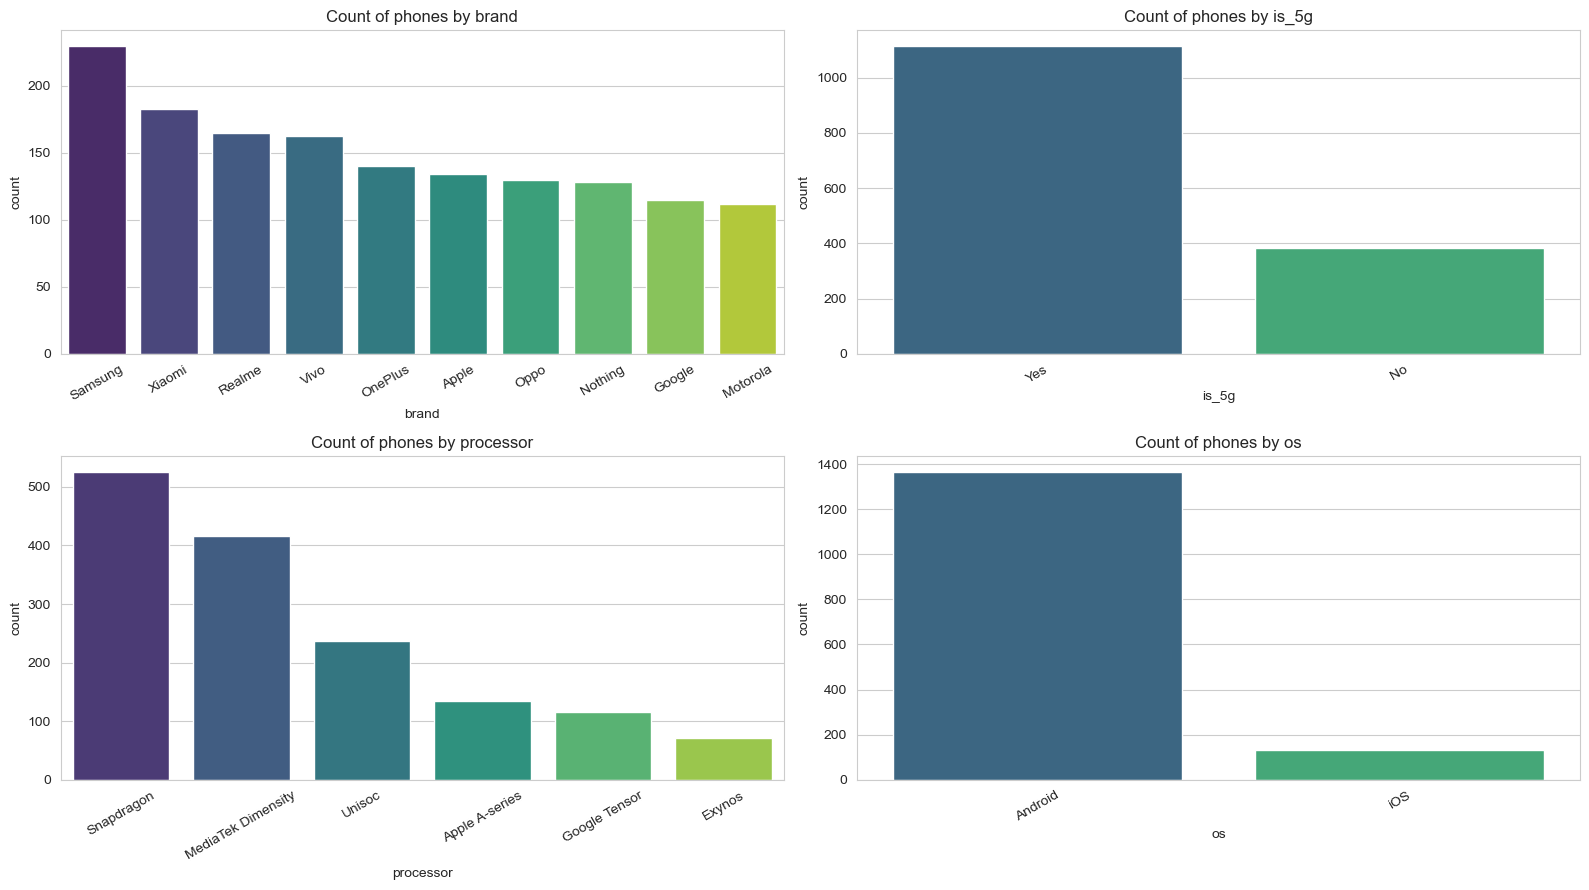

In [10]:
cat_cols = ["brand", "is_5g", "processor", "os"]

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax, palette="viridis")
    ax.set_title(f"Count of phones by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### 5.3 Bivariate Analysis — What affects price?

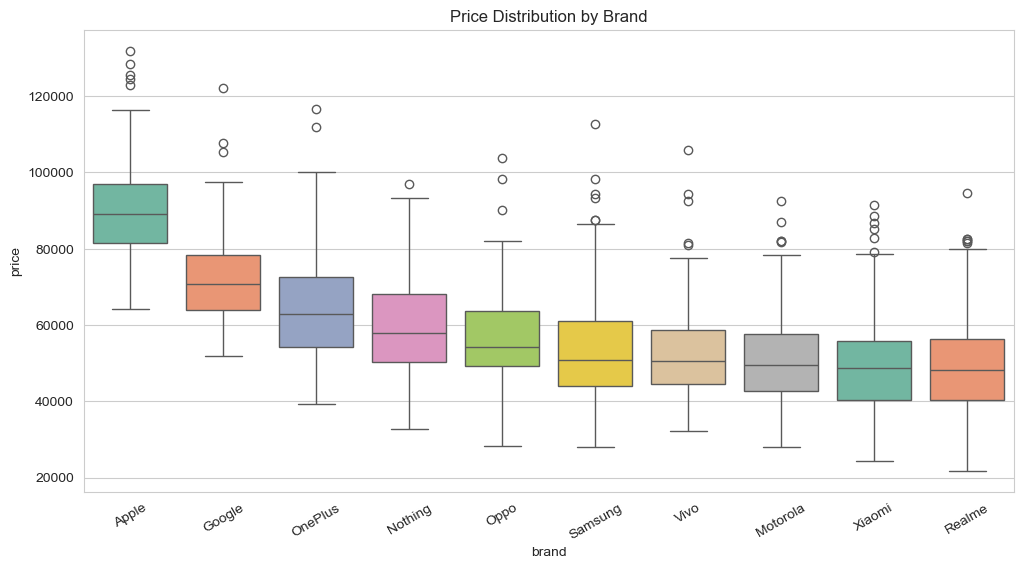

Average price by brand:


,avg_price
brand,
Apple,90119.0
Google,72215.0
OnePlus,64414.0
Nothing,60670.0
Oppo,56505.0
Samsung,53216.0
Vivo,52551.0
Motorola,51844.0
Realme,49535.0


In [11]:
plt.figure(figsize=(12, 6))
order = df.groupby("brand")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="brand", y="price", order=order, palette="Set2")
plt.title("Price Distribution by Brand")
plt.xticks(rotation=30)
plt.show()

print("Average price by brand:")
df.groupby("brand")["price"].mean().sort_values(ascending=False).round(0).to_frame("avg_price")

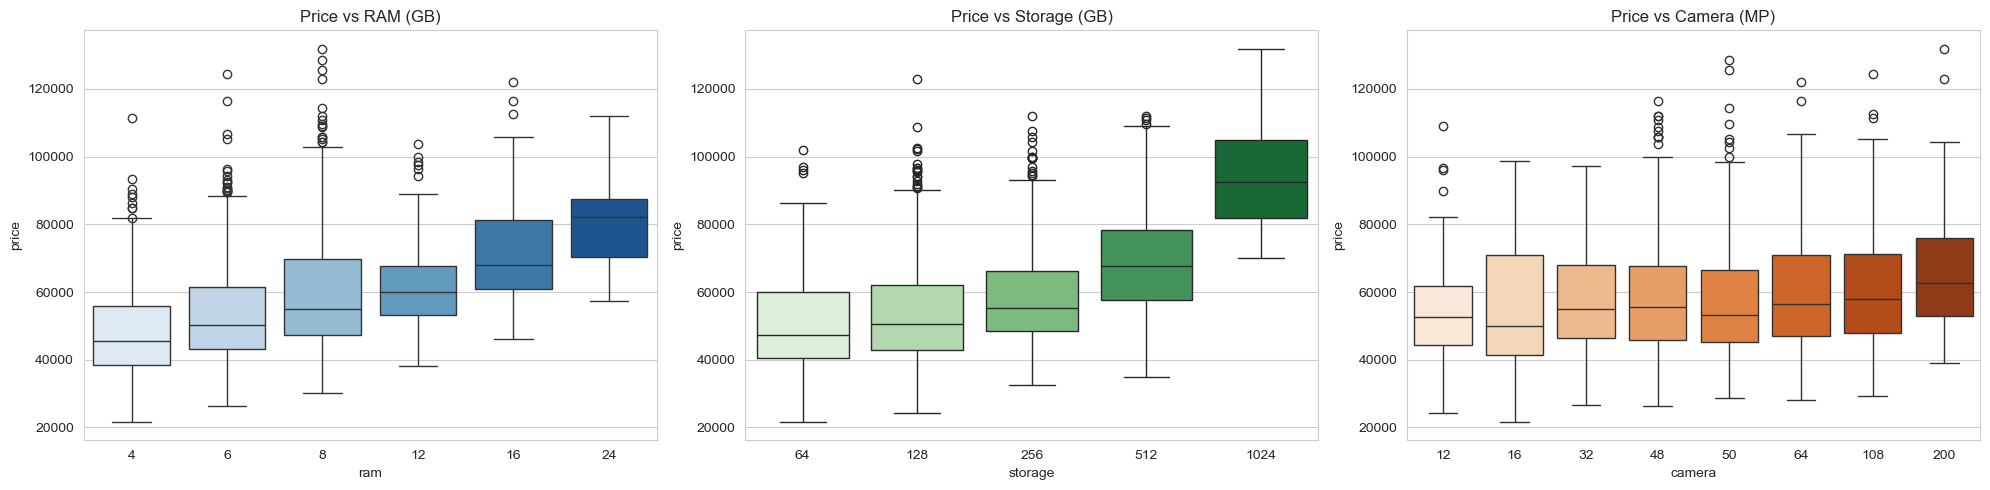

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=df, x="ram", y="price", ax=axes[0], palette="Blues");       axes[0].set_title("Price vs RAM (GB)")
sns.boxplot(data=df, x="storage", y="price", ax=axes[1], palette="Greens");  axes[1].set_title("Price vs Storage (GB)")
sns.boxplot(data=df, x="camera", y="price", ax=axes[2], palette="Oranges");  axes[2].set_title("Price vs Camera (MP)")
plt.tight_layout()
plt.show()

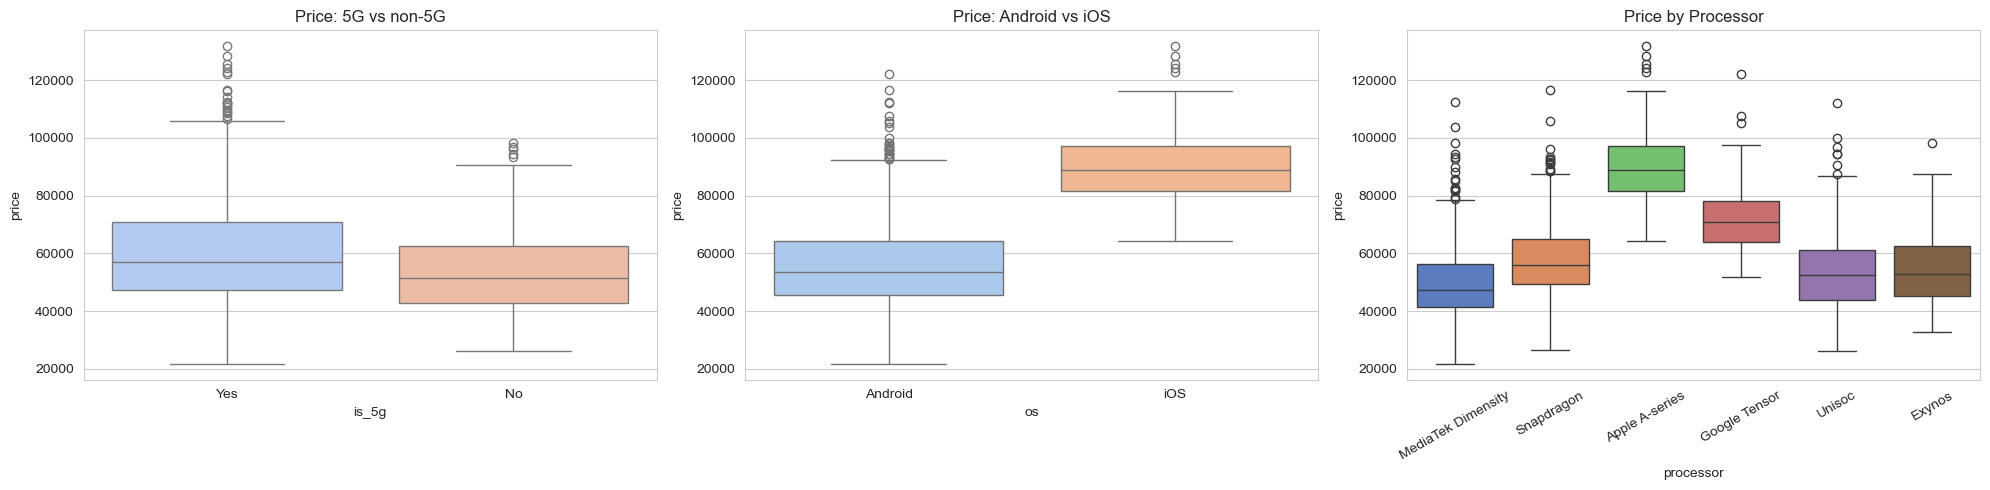

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=df, x="is_5g", y="price", ax=axes[0], palette="coolwarm");      axes[0].set_title("Price: 5G vs non-5G")
sns.boxplot(data=df, x="os", y="price", ax=axes[1], palette="pastel");           axes[1].set_title("Price: Android vs iOS")
sns.boxplot(data=df, x="processor", y="price", ax=axes[2], palette="muted");     axes[2].set_title("Price by Processor")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

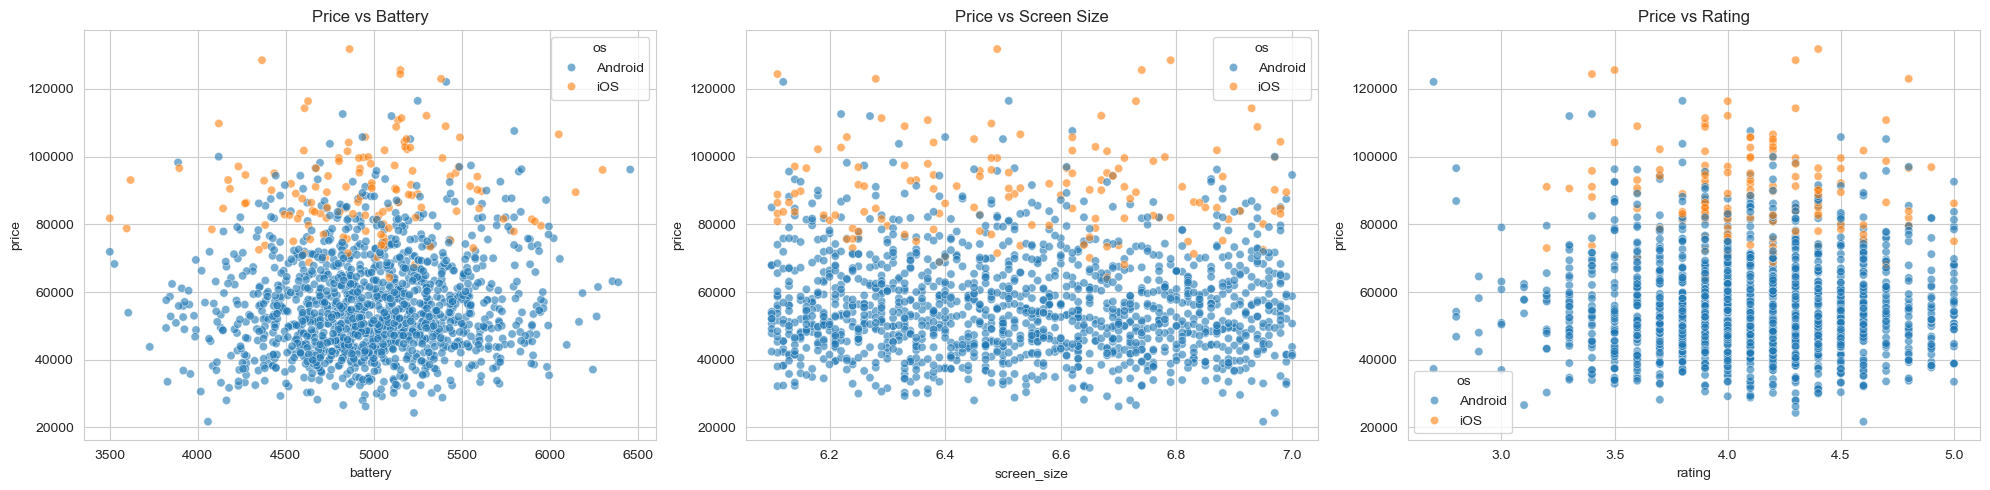

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(data=df, x="battery", y="price", hue="os", alpha=0.6, ax=axes[0]);      axes[0].set_title("Price vs Battery")
sns.scatterplot(data=df, x="screen_size", y="price", hue="os", alpha=0.6, ax=axes[1]);  axes[1].set_title("Price vs Screen Size")
sns.scatterplot(data=df, x="rating", y="price", hue="os", alpha=0.6, ax=axes[2]);       axes[2].set_title("Price vs Rating")
plt.tight_layout()
plt.show()

### 5.4 Correlation Analysis

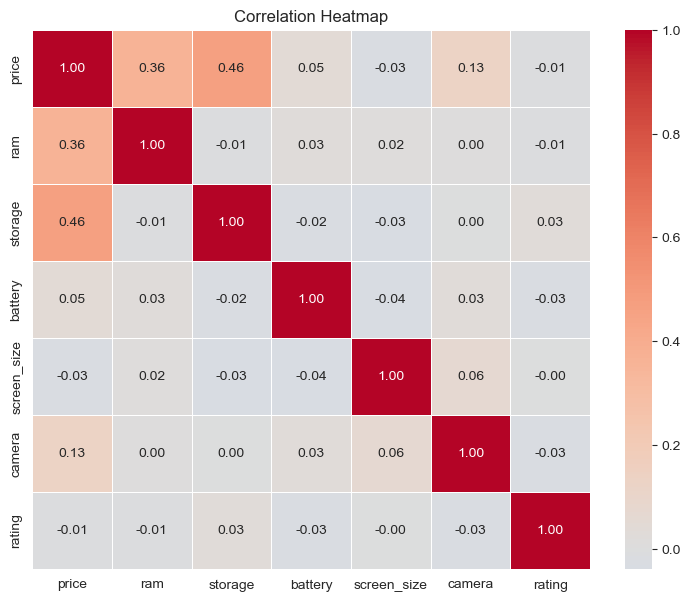

Correlation with price:


,correlation
storage,0.464
ram,0.359
camera,0.134
battery,0.045
rating,-0.009
screen_size,-0.026


In [15]:
plt.figure(figsize=(9, 7))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with price:")
corr["price"].drop("price").sort_values(ascending=False).round(3).to_frame("correlation")

### 5.5 Outlier Detection (IQR method)

,Outliers
price,27
ram,43
storage,264
battery,16
screen_size,0
camera,415
rating,7


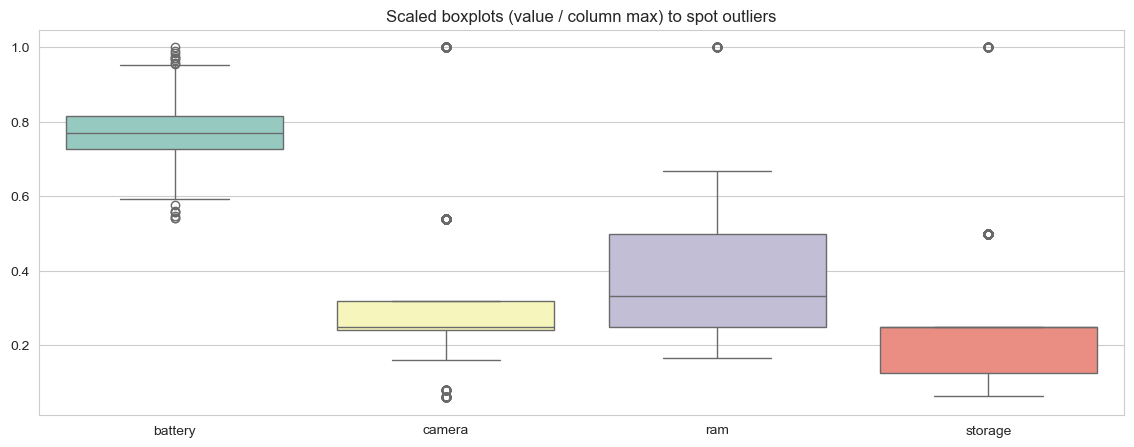

In [16]:
outlier_summary = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary[col] = int(((df[col] < low) | (df[col] > high)).sum())

display(pd.DataFrame.from_dict(outlier_summary, orient="index", columns=["Outliers"]))

plt.figure(figsize=(14, 5))
sns.boxplot(data=df[["battery", "camera", "ram", "storage"]].div(df[["battery", "camera", "ram", "storage"]].max()), palette="Set3")
plt.title("Scaled boxplots (value / column max) to spot outliers")
plt.show()

> Outliers here are **genuine** values (e.g. 1 TB storage, 200 MP camera, flagship prices), not errors, so they are kept.

### 5.6 Key Insights

In [17]:
print("1. Costliest brand  :", df.groupby("brand")["price"].mean().idxmax())
print("2. Cheapest brand   :", df.groupby("brand")["price"].mean().idxmin())
print("3. Avg price iOS    : ₹{:,.0f}".format(df[df.os == 'iOS']['price'].mean()))
print("4. Avg price Android: ₹{:,.0f}".format(df[df.os == 'Android']['price'].mean()))
print("5. Avg price 5G     : ₹{:,.0f}".format(df[df.is_5g == 'Yes']['price'].mean()))
print("6. Avg price non-5G : ₹{:,.0f}".format(df[df.is_5g == 'No']['price'].mean()))
print("7. Feature most correlated with price:", corr['price'].drop('price').abs().idxmax())

1. Costliest brand  : Apple
2. Cheapest brand   : Xiaomi
3. Avg price iOS    : ₹90,119
4. Avg price Android: ₹55,826
5. Avg price 5G     : ₹60,699
6. Avg price non-5G : ₹53,647
7. Feature most correlated with price: storage


## 6. Feature Engineering
We convert price into **3 classes** so we can use classification metrics (Accuracy, Precision, Recall, F1):

| Category | Price range |
|----------|-------------|
| Budget | below ₹45,000 |
| Mid-range | ₹45,000 – ₹70,000 |
| Premium | above ₹70,000 |

⚠️ `price` itself is **not** used as an input feature (that would leak the answer to the model).

price_category
Mid-range    820
Premium      352
Budget       328
Name: count, dtype: int64


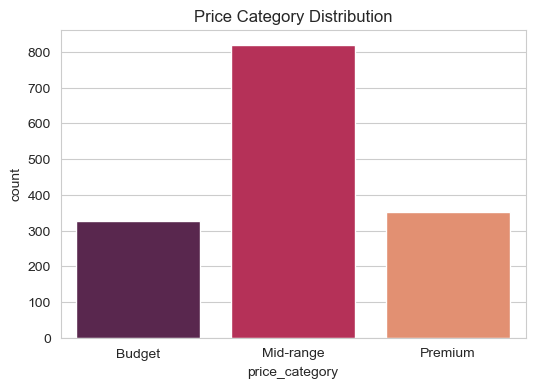

In [18]:
df["price_category"] = pd.cut(df["price"], bins=[0, 45000, 70000, np.inf],
                              labels=["Budget", "Mid-range", "Premium"])

print(df["price_category"].value_counts())
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="price_category", palette="rocket")
plt.title("Price Category Distribution")
plt.show()

In [19]:
feature_cols = ["brand", "ram", "storage", "battery", "screen_size", "camera",
                "rating", "is_5g", "processor", "os"]

X = pd.get_dummies(df[feature_cols], columns=["brand", "is_5g", "processor", "os"], drop_first=False)
y = df["price_category"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1200, 26)  Test: (300, 26)


## 7. Model Building & Evaluation

In [20]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=8, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=42),
}

scaler = StandardScaler().fit(X_train)
results = []
fitted = {}

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(scaler.transform(X_train), y_train)
        pred = model.predict(scaler.transform(X_test))
    else:
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
    fitted[name] = (model, pred)
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted"),
        "Recall":    recall_score(y_test, pred, average="weighted"),
        "F1-Score":  f1_score(y_test, pred, average="weighted"),
    })

results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8167,0.8178,0.8167,0.8145
Decision Tree,0.7933,0.7930,0.7933,0.7899
Random Forest,0.7733,0.7856,0.7733,0.7642


In [21]:
best_name = results_df["F1-Score"].idxmax()
best_model, best_pred = fitted[best_name]

print(f"🏆 Best model: {best_name}\n")
print(f"Accuracy  : {accuracy_score(y_test, best_pred):.4f}")
print(f"Precision : {precision_score(y_test, best_pred, average='weighted'):.4f}")
print(f"Recall    : {recall_score(y_test, best_pred, average='weighted'):.4f}")
print(f"F1 Score  : {f1_score(y_test, best_pred, average='weighted'):.4f}")
print("\nDetailed classification report:\n")
print(classification_report(y_test, best_pred))

🏆 Best model: Logistic Regression

Accuracy  : 0.8167
Precision : 0.8178
Recall    : 0.8167
F1 Score  : 0.8145

Detailed classification report:

              precision    recall  f1-score   support

      Budget       0.75      0.64      0.69        66
   Mid-range       0.80      0.88      0.84       164
     Premium       0.92      0.83      0.87        70

    accuracy                           0.82       300
   macro avg       0.82      0.78      0.80       300
weighted avg       0.82      0.82      0.81       300



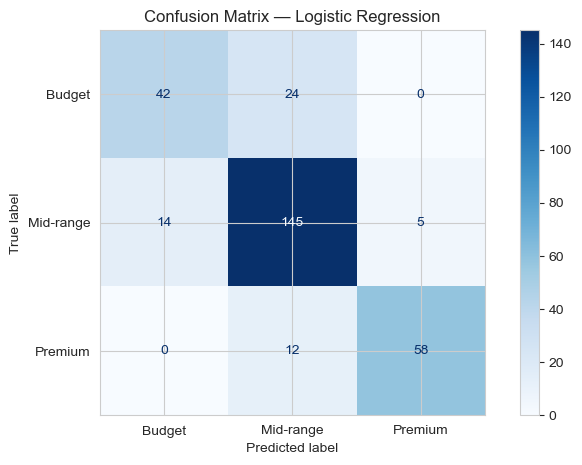

In [22]:
labels = ["Budget", "Mid-range", "Premium"]
cm = confusion_matrix(y_test, best_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

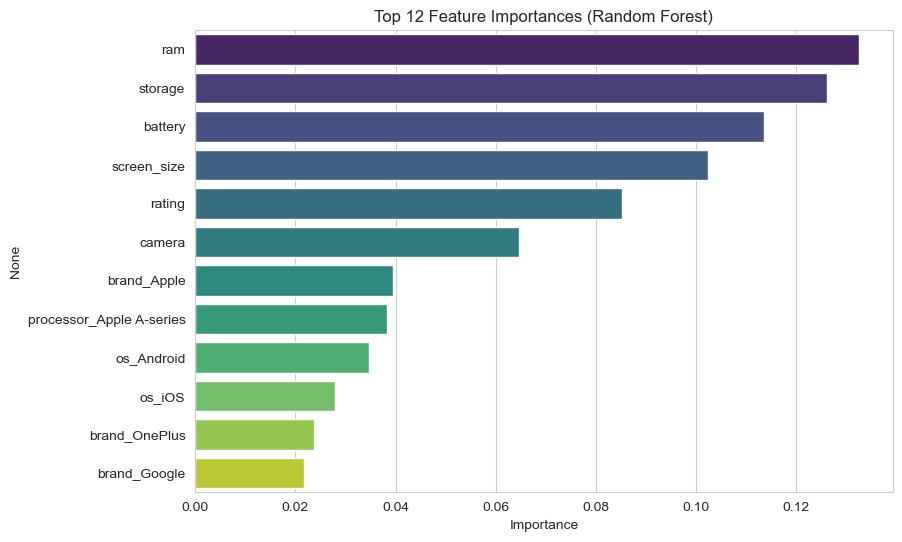

In [23]:
# Which features matter most? (uses a Random Forest)
rf = fitted["Random Forest"][0]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(12)

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, palette="viridis")
plt.title("Top 12 Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [24]:
# 5-fold cross-validation to confirm the score is stable
if best_name == "Logistic Regression":
    cv_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
else:
    cv_model = clone(models[best_name])
cv = cross_val_score(cv_model, X, y, cv=5, scoring="f1_weighted")
print("Model:", best_name)
print("CV F1 scores:", cv.round(3))
print(f"Mean F1: {cv.mean():.3f}  (+/- {cv.std():.3f})")

Model: Logistic Regression
CV F1 scores: [0.838 0.855 0.84  0.783 0.801]
Mean F1: 0.824  (+/- 0.027)


### Bonus: Price Estimator (Regression)
Besides the category, we train a Random Forest **regressor** to estimate the approximate price in ₹.

In [25]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, df["price"], test_size=0.2, random_state=42)
reg = RandomForestRegressor(n_estimators=300, random_state=42).fit(Xr_train, yr_train)
yr_pred = reg.predict(Xr_test)

print(f"R² Score : {r2_score(yr_test, yr_pred):.4f}")
print(f"MAE      : ₹{mean_absolute_error(yr_test, yr_pred):,.0f}")

R² Score : 0.8365
MAE      : ₹5,502


## 8. Phone Model Recommendation (e.g. Samsung → Galaxy A55)
Given a brand and its specifications, we recommend the **most likely phone models** of that brand.

**How it works:** we compare the entered specs (RAM, storage, battery, screen, camera, rating, 5G, processor and the estimated price) with every real phone of that brand in the dataset, take the **k closest phones** (K-Nearest Neighbours), and let their model names vote. The model with the most (distance-weighted) votes is the top recommendation.

In [26]:
spec_num = ["ram", "storage", "battery", "screen_size", "camera", "rating"]
rec_scaler = StandardScaler().fit(df[spec_num + ["price"]])

def _encode(frame, use_price):
    cols = spec_num + (["price"] if use_price else [])
    scaled = rec_scaler.transform(frame[spec_num + ["price"]])[:, [ (spec_num + ["price"]).index(c) for c in cols ]]
    extra = np.c_[(np.asarray(frame["is_5g"], dtype=object) == "Yes").astype(float),
                  (np.asarray(frame["processor"], dtype=object)[:, None] == np.array(sorted(df["processor"].unique()), dtype=object)).astype(float)]
    return np.c_[scaled, extra]

def recommend_models(brand, spec, est_price=None, ref=None, k=15, top_n=3):
    """Return (ranked list of (model, share%), closest real phone as a Series)."""
    ref = df if ref is None else ref
    sub = ref[ref["brand"] == brand].reset_index(drop=True)
    use_price = est_price is not None
    query = pd.DataFrame([{**spec, "price": est_price if use_price else df["price"].median()}])
    dist = np.linalg.norm(_encode(sub, use_price) - _encode(query, use_price), axis=1)
    idx = np.argsort(dist)[:min(k, len(sub))]
    weights = 1 / (dist[idx] + 1e-6)
    votes = pd.Series(weights, index=sub.loc[idx, "model"].values).groupby(level=0).sum()
    votes = (votes / votes.sum() * 100).sort_values(ascending=False)
    return list(votes.head(top_n).items()), sub.loc[idx[0]]

In [27]:
# How good is the recommender? (train on 80% of phones, test on the other 20% - specs only, price hidden)
train_ref = df.loc[X_train.index]
test_rows = df.loc[X_test.index]

top1 = top3 = 0
for _, row in test_rows.iterrows():
    spec = row[spec_num + ["is_5g", "processor"]].to_dict()
    ranked, _ = recommend_models(row["brand"], spec, est_price=None, ref=train_ref, top_n=3)
    names = [m for m, _ in ranked]
    top1 += names[0] == row["model"]
    top3 += row["model"] in names

n = len(test_rows)
print(f"Top-1 hit rate (exact model)      : {top1/n*100:.1f}%")
print(f"Top-3 hit rate (model in top 3)   : {top3/n*100:.1f}%")
print("Random guessing would give        : 20.0% (top-1) and 60.0% (top-3), since every brand has 5 models.")

Top-1 hit rate (exact model)      : 20.7%
Top-3 hit rate (model in top 3)   : 55.0%
Random guessing would give        : 20.0% (top-1) and 60.0% (top-3), since every brand has 5 models.


> **Note for your report:** each brand has 5 models, so random guessing is correct 20% of the time. In this dataset the specs of a model (RAM, storage, camera...) are almost identical across the models of one brand, so the model name cannot be predicted with high accuracy. The recommender is therefore a **"closest matching phones"** suggestion, not an exact identification. With real-world data (where each model has fixed specs) this approach would score much higher.

## 9. Dynamic Input — Predict Price & Recommend the Model for Any Phone
Run the next cell and type the specifications. The notebook will validate your input, then use the best model from Section 7 to show the **recommended phone model**, the **predicted price category**, the **estimated price** and the **confidence** of each category.

> **Input ranges:** each question only accepts values inside the range seen for that brand in the cleaned dataset (e.g. Apple RAM 4-8 GB), so predictions are never made far outside the data the model learned from.

In [28]:
def predict_category(user_row):
    """Predict with whichever model scored best (scales the input if needed)."""
    data = scaler.transform(user_row) if best_name == "Logistic Regression" else user_row
    return best_model.predict(data)[0], best_model.predict_proba(data)[0], best_model.classes_

def ask_choice(prompt, options):
    """Ask until the user types one of the allowed options (case-insensitive)."""
    lookup = {o.lower(): o for o in options}
    while True:
        val = input(f"{prompt} {options}: ").strip().lower()
        if val in lookup:
            return lookup[val]
        print("   ❌ Invalid choice, please type one of the listed options.")

def ask_number(prompt, lo, hi, cast=float):
    """Ask until the user types a number in [lo, hi]."""
    while True:
        try:
            val = cast(input(f"{prompt} ({lo}-{hi}): ").strip())
            if lo <= val <= hi:
                return val
            print(f"   ❌ Value must be between {lo} and {hi}.")
        except ValueError:
            print("   ❌ Please enter a valid number.")

def predict_phone():
    print("=" * 60)
    print("       📱 MOBILE PHONE PRICE & MODEL PREDICTOR")
    print("=" * 60)

    brand   = ask_choice("Brand", sorted(df["brand"].unique()))
    os_name = "iOS" if brand == "Apple" else "Android"
    print(f"   ℹ️  OS automatically set to {os_name}")

    if brand == "Apple":
        processor = "Apple A-series"
        print("   ℹ️  Processor automatically set to Apple A-series")
    elif brand == "Google":
        processor = "Google Tensor"
        print("   ℹ️  Processor automatically set to Google Tensor")
    else:
        allowed = sorted(df.loc[df["brand"] == brand, "processor"].unique())
        processor = ask_choice("Processor", allowed)

    # Valid ranges come from the real phones of the chosen brand in the cleaned data
    sub = df[df["brand"] == brand]
    def rng(col, cast):
        return cast(sub[col].min()), cast(sub[col].max())

    ram     = ask_number("RAM in GB",            *rng("ram", int),         int)
    storage = ask_number("Storage in GB",        *rng("storage", int),     int)
    battery = ask_number("Battery in mAh",       *rng("battery", int),     int)
    screen  = ask_number("Screen size in inches",*rng("screen_size", float), float)
    camera  = ask_number("Main camera in MP",    *rng("camera", int),      int)
    rating  = ask_number("User rating",          *rng("rating", float),    float)
    is_5g   = "Yes" if brand == "Apple" else ask_choice("5G support", ["Yes", "No"])

    # Build one-row dataframe in the same format as training data
    user = pd.DataFrame([{
        "brand": brand, "ram": ram, "storage": storage, "battery": battery,
        "screen_size": screen, "camera": camera, "rating": rating,
        "is_5g": is_5g, "processor": processor, "os": os_name}])
    user = pd.get_dummies(user, columns=["brand", "is_5g", "processor", "os"])
    user = user.reindex(columns=X.columns, fill_value=0)

    category, probs, classes = predict_category(user)
    est = reg.predict(user)[0]

    spec = {"ram": ram, "storage": storage, "battery": battery, "screen_size": screen,
            "camera": camera, "rating": rating, "is_5g": is_5g, "processor": processor}
    ranked, closest = recommend_models(brand, spec, est_price=est)

    print("\n" + "=" * 60)
    print("                    📊 RESULT")
    print("=" * 60)
    print(f"  Phone          : {brand} | {ram}GB RAM | {storage}GB | {battery}mAh | {camera}MP | {os_name}")
    print(f"  Price Category : {category}")
    print(f"  Estimated Price: ₹{est:,.0f}  (approx. range ₹{est*0.9:,.0f} – ₹{est*1.1:,.0f})")
    print(f"  Recommended    : {brand} {ranked[0][0]}   <-- best matching model")
    print("  Other matches  :")
    for m, share in ranked[1:]:
        print(f"      {brand} {m:<18} ({share:.0f}% match)")
    print(f"  Closest listing: {brand} {closest['model']} | {closest['ram']}GB/{closest['storage']}GB | "
          f"{closest['camera']}MP | {closest['battery']}mAh | ₹{closest['price']:,.0f}")
    print("  Confidence (price category):")
    for cls, p in zip(classes, probs):
        print(f"      {cls:<10} {p*100:5.1f}%  {'█' * int(p*30)}")
    print("=" * 60)

def run_predictor():
    while True:
        predict_phone()
        again = input("\nPredict another phone? (yes/no): ").strip().lower()
        if again not in ("y", "yes"):
            print("Thank you! 👋")
            break

run_predictor()

       📱 MOBILE PHONE PRICE & MODEL PREDICTOR


Brand ['Apple', 'Google', 'Motorola', 'Nothing', 'OnePlus', 'Oppo', 'Realme', 'Samsung', 'Vivo', 'Xiaomi']:  Google


   ℹ️  OS automatically set to Android
   ℹ️  Processor automatically set to Google Tensor


RAM in GB (4-24):  6
Storage in GB (64-1024):  128
Battery in mAh (3821-6058):  5000
Screen size in inches (6.1-6.96):  6.1
Main camera in MP (12-200):  48
User rating (2.7-5.0):  4.8
5G support ['Yes', 'No']:  yes



                    📊 RESULT
  Phone          : Google | 6GB RAM | 128GB | 5000mAh | 48MP | Android
  Price Category : Mid-range
  Estimated Price: ₹60,045  (approx. range ₹54,041 – ₹66,050)
  Recommended    : Google Pixel 9a   <-- best matching model
  Other matches  :
      Google Pixel 8a           (19% match)
      Google Pixel 9            (18% match)
  Closest listing: Google Pixel 9 Pro XL | 8GB/256GB | 48MP | 4787mAh | ₹67,900
  Confidence (price category):
      Budget       0.2%  
      Mid-range   90.2%  ███████████████████████████
      Premium      9.6%  ██



Predict another phone? (yes/no):  no


Thank you! 👋


## 10. Final Model Scores (Summary)

In [29]:
print("=" * 50)
print(f"MODEL USED  : {best_name}")
print("=" * 50)
print(f"Accuracy    : {accuracy_score(y_test, best_pred)*100:.2f}%")
print(f"Precision   : {precision_score(y_test, best_pred, average='weighted')*100:.2f}%")
print(f"Recall      : {recall_score(y_test, best_pred, average='weighted')*100:.2f}%")
print(f"F1 Score    : {f1_score(y_test, best_pred, average='weighted')*100:.2f}%")
print("=" * 50)

MODEL USED  : Logistic Regression
Accuracy    : 81.67%
Precision   : 81.78%
Recall      : 81.67%
F1 Score    : 81.45%


## 11. Conclusion
* The raw file contained **duplicates, missing values and logical errors** (iPhones on Android, wrong chip/brand pairs, 5G-less iPhones). All were corrected and saved to `mobile_phone_price_eda_cleaned.csv`.
* **Brand, RAM, storage and OS** are the strongest drivers of price; Apple and Google sit in the premium segment.
* A KNN-based recommender suggests the closest matching phone model of the chosen brand (see Section 8 for its honest hit-rate).
* The classification model predicts the price category with the Accuracy / Precision / Recall / F1 shown above, and the dynamic input section lets anyone test a new phone.

**Future scope:** add more real-world features (launch year, display type, chipset benchmark scores), try Gradient Boosting / XGBoost, and deploy the predictor with Streamlit.